# Data Stream v2 — Tiền xử lý & khám phá dữ liệu

Dữ liệu review cấp user phục vụ feedback của thầy: gom game theo nhà phát hành / thể loại → tìm user
review tích cực một game trong nhóm → gợi ý game cùng nhóm.

Nguồn:
- `data/Data Stream_v2.xlsx`: 3 reviewer/game (nhiều / tầm trung / ít game sở hữu) kèm giờ chơi, vote, trích đoạn review.
- `data/Data Stream.xlsx` (v1): chỉ lấy cột **Publisher** để ghép theo AppID.

Đầu ra (file mới, không ghi đè file gốc): `data/v2_reviews_clean.csv`, `data/v2_games.csv`.

Lưu ý: mọi nhận xét là **tương quan** trên mẫu nhỏ (≈ 270 review), không suy ra nguyên nhân.

In [1]:
import re
import zipfile
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})

TIER_ORDER = ["Ít game nhất", "Tầm trung", "Nhiều game nhất"]
TIER_EN = {"Ít game nhất": "low", "Tầm trung": "mid", "Nhiều game nhất": "high"}

## 1. Đọc dữ liệu
Môi trường chưa có `openpyxl` nên `pd.read_excel` không chạy. Đọc trực tiếp XML trong file xlsx,
lấy **giá trị thô dạng chuỗi** cho mọi ô (giữ nguyên Steam ID như Excel lưu), ép kiểu sau ở bước làm sạch.

In [2]:
NS = {"m": "http://schemas.openxmlformats.org/spreadsheetml/2006/main"}

def read_xlsx_raw(path):
    """Đọc sheet đầu tiên của file xlsx thành DataFrame toàn chuỗi (dòng 1 làm header)."""
    with zipfile.ZipFile(path) as z:
        shared = []
        if "xl/sharedStrings.xml" in z.namelist():
            for si in ET.fromstring(z.read("xl/sharedStrings.xml")).findall("m:si", NS):
                shared.append("".join(t.text or "" for t in si.iter(f"{{{NS['m']}}}t")))
        sheet = ET.fromstring(z.read("xl/worksheets/sheet1.xml"))
    rows = []
    for row in sheet.iter(f"{{{NS['m']}}}row"):
        rec = {}
        for c in row.findall("m:c", NS):
            col = re.match(r"[A-Z]+", c.attrib["r"]).group()
            v = c.find("m:v", NS)
            if c.attrib.get("t") == "s" and v is not None:
                rec[col] = shared[int(v.text)]
            elif c.attrib.get("t") == "inlineStr":
                rec[col] = "".join(t.text or "" for t in c.iter(f"{{{NS['m']}}}t"))
            else:
                rec[col] = v.text if v is not None else None
        rows.append(rec)
    df = pd.DataFrame(rows)
    df = df[sorted(df.columns, key=lambda s: (len(s), s))]
    df.columns = df.iloc[0]
    return df.iloc[1:].reset_index(drop=True).astype(object)

raw = read_xlsx_raw("data/Data Stream_v2.xlsx")
v1_raw = read_xlsx_raw("data/Data Stream.xlsx")
print("v2:", raw.shape, "| v1:", v1_raw.shape)

v2: (299, 14) | v1: (203, 7)


In [3]:
display(raw.head(6))
display(raw.tail(3))

,STT (Hạng),Tên Game,AppID,Phân loại reviewer,Steam ID người viết,Số game sở hữu,Số review đã viết,Giờ chơi khi viết (Giờ),Tổng giờ chơi hiện tại (Giờ),Điểm hữu ích,Vote hữu ích,Vote hài hước,Đánh giá (% Tích cực / Tiêu cực),Trích đoạn nội dung Review
0,1,Counter-Strike 2,730,Nhiều game nhất,7.6561198012340992E+16,3450,210,1420.0,3850.0,0.96,840,120,88% Tích cực (12% Tiêu cực),"""Game nâng cấp đồ họa đẹp hơn, dù còn vài lỗi nhỏ nhưng bắn vẫn rất cuốn."""
1,None,None,None,Tầm trung,7.6561198150020992E+16,185,12,215.5,480.0,0.78,45,6,88% Tích cực (12% Tiêu cực),"""Cơ chế khói mới rất hay, cần tối ưu thêm hiệu năng trên máy yếu."""
2,None,None,None,Ít game nhất,7.6561199011231008E+16,2,1,85.0,140.0,0.52,4,1,12% Tiêu cực (88% Tích cực),"""Chưa quen với hitbox mới, cảm giác bắn không như CS:GO."""
3,2,Dota 2,570,Nhiều game nhất,7.6561197998812E+16,2890,185,3200.0,7100.0,0.94,620,95,80% Tích cực (20% Tiêu cực),"""Meta thay đổi liên tục, game MOBA có chiều sâu nhất hiện tại."""
4,None,None,None,Tầm trung,7.6561198210032E+16,140,8,850.0,1650.0,0.81,68,12,80% Tích cực (20% Tiêu cực),"""Bản update bản đồ rộng hơn làm game đa dạng chiến thuật hơn hẳn."""
5,None,None,None,Ít game nhất,7.6561199123452E+16,1,1,42.0,95.0,0.48,2,0,20% Tiêu cực (80% Tích cực),"""Game quá khó cho người mới bắt đầu, cộng đồng hơi toxic."""


,STT (Hạng),Tên Game,AppID,Phân loại reviewer,Steam ID người viết,Số game sở hữu,Số review đã viết,Giờ chơi khi viết (Giờ),Tổng giờ chơi hiện tại (Giờ),Điểm hữu ích,Vote hữu ích,Vote hài hước,Đánh giá (% Tích cực / Tiêu cực),Trích đoạn nội dung Review
296,100,Satisfactory,526870,Nhiều game nhất,7.656119804455E+16,2200,98,280.0,750.0,0.98,1420,110,97% Tích cực (3% Tiêu cực),"""Xây dựng nhà máy góc nhìn thứ nhất đỉnh nhất, quy hoạch băng tải cực gây ng..."
297,None,None,None,Tầm trung,7.656119815566E+16,135,9,110.0,290.0,0.90,115,8,97% Tích cực (3% Tiêu cực),"""Đồ họa thế giới ngoài hành tinh đẹp mắt, tự động hóa dây chuyền sản xuất rấ..."
298,None,None,None,Ít game nhất,7.656119917788E+16,2,1,32.0,85.0,0.61,8,0,97% Tích cực (3% Tiêu cực),"""Chơi Co-op cùng bạn bè xây nhà máy siêu vui."""


In [4]:
raw.info()
display(pd.DataFrame({"missing": raw.isna().sum(), "n_unique": raw.nunique()}).T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 14 columns):
 #   Column                            Non-Null Count  Dtype 
---  ------                            --------------  ----- 
 0   STT (Hạng)                        100 non-null    object
 1   Tên Game                          100 non-null    object
 2   AppID                             100 non-null    object
 3   Phân loại reviewer                299 non-null    object
 4   Steam ID người viết               299 non-null    object
 5   Số game sở hữu                    299 non-null    object
 6   Số review đã viết                 299 non-null    object
 7   Giờ chơi khi viết (Giờ)           299 non-null    object
 8   Tổng giờ chơi hiện tại (Giờ)      299 non-null    object
 9   Điểm hữu ích                      299 non-null    object
 10  Vote hữu ích                      299 non-null    object
 11  Vote hài hước                     299 non-null    object
 12  Đánh giá (% Tích cực /

,STT (Hạng),Tên Game,AppID,Phân loại reviewer,Steam ID người viết,Số game sở hữu,Số review đã viết,Giờ chơi khi viết (Giờ),Tổng giờ chơi hiện tại (Giờ),Điểm hữu ích,Vote hữu ích,Vote hài hước,Đánh giá (% Tích cực / Tiêu cực),Trích đoạn nội dung Review
missing,199,199,199,0,0,0,0,0,0,0,0,0,0,0
n_unique,100,92,92,3,298,79,65,69,91,51,103,62,43,275


Cột `STT`, `Tên Game`, `AppID` chỉ ghi ở dòng đầu của mỗi game (kiểu ô gộp trong Excel) → missing ở 2/3 số dòng.
Toàn bộ cột đang là chuỗi; xem nhanh giá trị của các cột phân loại và mô tả các cột số (ép tạm sang số):

In [5]:
display(raw["Phân loại reviewer"].value_counts().to_frame())
display(raw["Đánh giá (% Tích cực / Tiêu cực)"].value_counts().head(8).to_frame())

num_cols_raw = ["Số game sở hữu", "Số review đã viết", "Giờ chơi khi viết (Giờ)", "Tổng giờ chơi hiện tại (Giờ)",
                "Điểm hữu ích", "Vote hữu ích", "Vote hài hước"]
display(raw[num_cols_raw].apply(pd.to_numeric, errors="coerce")
        .describe(percentiles=[.05, .25, .5, .75, .95]).T.round(2))

,count
Phân loại reviewer,
Nhiều game nhất,100
Tầm trung,100
Ít game nhất,99


,count
Đánh giá (% Tích cực / Tiêu cực),
97% Tích cực (3% Tiêu cực),54
96% Tích cực (4% Tiêu cực),27
98% Tích cực (2% Tiêu cực),21
92% Tích cực (8% Tiêu cực),21
88% Tích cực (12% Tiêu cực),18
90% Tích cực (10% Tiêu cực),16
86% Tích cực (14% Tiêu cực),15
91% Tích cực (9% Tiêu cực),13


,count,mean,std,min,5%,25%,50%,75%,95%,max
0,,,,,,,,,,
Số game sở hữu,299.0,1023.90,1433.41,1.0,2.00,3.00,140.00,2200.00,3900.00,5400.00
Số review đã viết,299.0,54.81,82.73,1.0,1.00,1.00,10.00,95.00,212.00,420.00
Giờ chơi khi viết (Giờ),299.0,163.45,345.32,6.0,12.00,25.00,55.00,140.00,653.00,3200.00
Tổng giờ chơi hiện tại (Giờ),299.0,413.13,841.47,12.0,28.00,57.50,120.00,385.00,1805.00,7100.00
Điểm hữu ích,299.0,0.79,0.16,0.4,0.51,0.63,0.83,0.92,0.98,0.99
Vote hữu ích,299.0,390.01,565.49,2.0,4.00,9.50,75.00,680.00,1650.00,2400.00
Vote hài hước,299.0,53.57,91.05,0.0,0.00,1.00,9.00,85.00,210.00,580.00


In [6]:
print("Steam ID — 5 giá trị thô đầu:", raw["Steam ID người viết"].head().tolist())
print("Độ dài chuỗi Steam ID:", raw["Steam ID người viết"].str.len().value_counts().to_dict())
print("Ví dụ review thô:", repr(raw["Trích đoạn nội dung Review"].iloc[0]))

Steam ID — 5 giá trị thô đầu: ['7.6561198012340992E+16', '7.6561198150020992E+16', '7.6561199011231008E+16', '7.6561197998812E+16', '7.6561198210032E+16']
Độ dài chuỗi Steam ID: {22: 215, 20: 54, 19: 24, 18: 6}
Ví dụ review thô: '"Game nâng cấp đồ họa đẹp hơn, dù còn vài lỗi nhỏ nhưng bắn vẫn rất cuốn."'


**Nhận xét (đọc dữ liệu)**
- 299 dòng × 14 cột. Mỗi STT có 3 reviewer theo bậc số game sở hữu; `Ít game nhất` có 99 dòng → thiếu 1 dòng.
- Steam ID được Excel lưu ở dạng **số thực** (`7.65...E+16`). Steam ID thật có 17 chữ số, vượt giới hạn
  chính xác của float (≈ 15–16 chữ số) → các chữ số cuối đã bị làm tròn, **không tra ngược ra tài khoản thật được**.
  Chỉ dùng như mã định danh user trong bảng này.
- Cột `Đánh giá` là % tích cực/tiêu cực của **game**, không phải của review (xem §2.4).
- Review là trích đoạn **tiếng Việt**, có dấu ngoặc kép bao ngoài.

## 2. Làm sạch

In [7]:
step_log = []

def log_step(step, before, after, note=""):
    step_log.append({"bước": step, "trước": before, "sau": after, "loại": before - after, "ghi chú": note})
    print(f"[{step}] {before} → {after} (loại {before - after}). {note}")

### 2.1 Đổi tên cột, điền giá trị ô gộp, ép kiểu

In [8]:
df = raw.rename(columns={
    "STT (Hạng)": "rank", "Tên Game": "game_name", "AppID": "app_id", "Phân loại reviewer": "reviewer_tier",
    "Steam ID người viết": "steamid", "Số game sở hữu": "games_owned", "Số review đã viết": "num_reviews",
    "Giờ chơi khi viết (Giờ)": "playtime_at_review", "Tổng giờ chơi hiện tại (Giờ)": "playtime_forever",
    "Điểm hữu ích": "helpful_score", "Vote hữu ích": "votes_helpful", "Vote hài hước": "votes_funny",
    "Đánh giá (% Tích cực / Tiêu cực)": "rating_raw", "Trích đoạn nội dung Review": "review_text",
}).copy()

df[["rank", "game_name", "app_id"]] = df[["rank", "game_name", "app_id"]].ffill()
NUM = ["games_owned", "num_reviews", "playtime_at_review", "playtime_forever",
       "helpful_score", "votes_helpful", "votes_funny"]
df[NUM] = df[NUM].apply(pd.to_numeric)
df[["rank", "app_id"]] = df[["rank", "app_id"]].astype(int)
# steamid: giữ nguyên chuỗi như Excel lưu (đã mất chính xác), không ép sang số
df["steamid"] = df.steamid.str.strip()
df["reviewer_tier"] = pd.Categorical(df.reviewer_tier, categories=TIER_ORDER, ordered=True)
print("missing sau ffill:", df.isna().sum()[lambda s: s > 0].to_dict() or "không còn")
display(df.dtypes.to_frame("dtype").T)

missing sau ffill: không còn


,rank,game_name,app_id,reviewer_tier,steamid,games_owned,num_reviews,playtime_at_review,playtime_forever,helpful_score,votes_helpful,votes_funny,rating_raw,review_text
dtype,int64,object,int64,category,object,int64,int64,float64,float64,float64,int64,int64,object,object


### 2.2 Làm sạch text
Bỏ dấu ngoặc kép bao ngoài, gộp khoảng trắng.

In [9]:
df["review_text"] = (df.review_text.str.strip().str.strip('"“”').str.replace(r"\s+", " ", regex=True).str.strip())
df["text_len"] = df.review_text.str.len()
df["word_count"] = df.review_text.str.split().str.len()
print("review rỗng:", (df.text_len == 0).sum())
display(df[["game_name", "reviewer_tier", "review_text"]].head(3))

review rỗng: 0


,game_name,reviewer_tier,review_text
0,Counter-Strike 2,Nhiều game nhất,"Game nâng cấp đồ họa đẹp hơn, dù còn vài lỗi nhỏ nhưng bắn vẫn rất cuốn."
1,Counter-Strike 2,Tầm trung,"Cơ chế khói mới rất hay, cần tối ưu thêm hiệu năng trên máy yếu."
2,Counter-Strike 2,Ít game nhất,"Chưa quen với hitbox mới, cảm giác bắn không như CS:GO."


### 2.3 Game bị lặp
100 STT nhưng số AppID duy nhất ít hơn. Kiểm tra các STT trùng AppID và so sánh nội dung giữa các bản.

In [10]:
print("Số STT:", df["rank"].nunique(), "| số AppID:", df.app_id.nunique())
rank_per_app = df.groupby("app_id")["rank"].unique()
dup_apps = rank_per_app[rank_per_app.str.len() > 1]
dup_tbl = pd.DataFrame({"game_name": df.groupby("app_id").game_name.first()[dup_apps.index],
                        "ranks": dup_apps.map(list)})
display(dup_tbl)

# So sánh các bản lặp, bỏ qua rank và steamid
cmp_cols = ["reviewer_tier"] + NUM + ["rating_raw", "review_text"]
same = (df[df.app_id.isin(dup_apps.index)]
          .groupby(["app_id", "reviewer_tier"], observed=True)[cmp_cols[1:]]
          .nunique().le(1).all(axis=1))
print("Mọi bản lặp giống hệt nhau (trừ rank, steamid):", bool(same.all()))

Số STT: 100 | số AppID: 92


,game_name,ranks
app_id,,
413150,Stardew Valley,"[14, 88]"
433340,Slime Rancher,"[62, 84]"
526870,Satisfactory,"[36, 100]"
632360,Risk of Rain 2,"[44, 94]"
753640,Outer Wilds,"[50, 90]"
1158310,Crusader Kings III,"[46, 98]"
1868140,Dave the Diver,"[49, 89]"
1966720,Lethal Company,"[47, 97]"


Mọi bản lặp giống hệt nhau (trừ rank, steamid): True


In [11]:
n0 = len(df)
first_rank = df.groupby("app_id")["rank"].transform("min")
df = df[df["rank"] == first_rank].copy()
log_step("bỏ game lặp (giữ STT nhỏ nhất)", n0, len(df), f"{len(dup_apps)} game lặp")

n0 = len(df)
df = df.drop_duplicates(["app_id", "reviewer_tier"])
log_step("trùng (app_id, reviewer_tier)", n0, len(df))
dup_sid = df[df.steamid.duplicated(keep=False)]
print("steamid trùng:")
display(dup_sid[["game_name", "reviewer_tier", "steamid", "games_owned", "num_reviews"]])

tiers_per_game = df.groupby("app_id").reviewer_tier.nunique()
print("Game thiếu bậc reviewer:")
display(df[df.app_id.isin(tiers_per_game[tiers_per_game < 3].index)][["game_name", "reviewer_tier"]])

[bỏ game lặp (giữ STT nhỏ nhất)] 299 → 275 (loại 24). 8 game lặp
[trùng (app_id, reviewer_tier)] 275 → 275 (loại 0). 
steamid trùng:


,game_name,reviewer_tier,steamid,games_owned,num_reviews
21,Helldivers 2,Nhiều game nhất,7.6561198022338E+16,1850,88
236,Total War: THREE KINGDOMS,Nhiều game nhất,7.6561198022338E+16,2800,130


Game thiếu bậc reviewer:


,game_name,reviewer_tier
108,7 Days to Die,Nhiều game nhất
109,7 Days to Die,Tầm trung


**Nhận xét (trùng lặp)**
- 8 game xuất hiện 2 lần (STT 84–100 chép lại game đã có), bản sau giống hệt bản đầu trừ Steam ID → bỏ, còn 275 dòng / 92 game.
- 1 Steam ID trùng giữa Helldivers 2 và Total War: THREE KINGDOMS nhưng số game sở hữu khác nhau (1.850 vs 2.800)
  → không phải cùng 1 người, chỉ là va chạm ID. Vì vậy dùng `user_id` riêng cho mỗi dòng (tạo ở §2.7).
- 7 Days to Die thiếu reviewer bậc "Ít game nhất" → giữ nguyên, không tự sinh thêm.

### 2.4 Tách cột đánh giá → `game_pos_pct` và `voted_up`
Cột `rating_raw` có 2 dạng: `88% Tích cực (12% Tiêu cực)` và `12% Tiêu cực (88% Tích cực)`.
Con số % giống nhau trong cùng game (là % của game), nhưng **thứ tự chữ** khác nhau giữa các reviewer.
Giả thuyết: dạng bắt đầu bằng "Tiêu cực" ↔ review đó **không recommend**. Kiểm chứng bằng cách đọc text bên dưới.

In [12]:
pat = r"^\s*(\d+)%\s*(Tích cực|Tiêu cực)\s*\(\s*(\d+)%\s*(Tích cực|Tiêu cực)\s*\)\s*$"
parts = df.rating_raw.str.extract(pat)
print("Dòng không khớp mẫu:", parts[0].isna().sum())
pos_first = parts[1].eq("Tích cực")
df["game_pos_pct"] = np.where(pos_first, parts[0], parts[2]).astype(float)
df["game_neg_pct"] = 100 - df.game_pos_pct
assert (np.where(pos_first, parts[2], parts[0]).astype(float) == df.game_neg_pct).all()
df["voted_up"] = pos_first.astype(bool)

print("% tích cực khác nhau trong cùng 1 game:", (df.groupby("app_id").game_pos_pct.nunique() > 1).sum(), "game")
print("voted_up:", df.voted_up.value_counts().to_dict())

Dòng không khớp mẫu: 0
% tích cực khác nhau trong cùng 1 game: 0 game
voted_up: {True: 239, False: 36}


In [13]:
pd.set_option("display.max_colwidth", 120)
print("Mẫu review gán voted_up = False:")
display(df.loc[~df.voted_up, ["game_name", "reviewer_tier", "review_text"]].head(12))
print("Mẫu review gán voted_up = True của cùng các game:")
display(df.loc[df.voted_up & df.app_id.isin(df.loc[~df.voted_up, "app_id"].head(4)),
               ["game_name", "reviewer_tier", "review_text"]])
pd.set_option("display.max_colwidth", 80)

Mẫu review gán voted_up = False:


,game_name,reviewer_tier,review_text
2,Counter-Strike 2,Ít game nhất,"Chưa quen với hitbox mới, cảm giác bắn không như CS:GO."
5,Dota 2,Ít game nhất,"Game quá khó cho người mới bắt đầu, cộng đồng hơi toxic."
7,PUBG: BATTLEGROUNDS,Tầm trung,Thi thoảng vẫn gặp hack/cheater làm giảm trải nghiệm.
10,Apex Legends,Tầm trung,Matchmaking phân bậc xếp hạng chưa được cân bằng lắm.
14,Grand Theft Auto V,Ít game nhất,Tải game rất lâu và dung lượng ổ cứng chiếm quá nhiều.
19,Rust,Tầm trung,"Yêu cầu cày cuốc tốn quá nhiều thời gian, rủ đông bạn chơi mới vui."
20,Rust,Ít game nhất,Vừa vào game chưa kịp xây nhà đã bị người chơi cũ hạ gục.
23,Helldivers 2,Ít game nhất,Game đôi khi bị văng ra ngoài khi đang trong trận đấu đông địch.
29,Team Fortress 2,Ít game nhất,Server thi thoảng vẫn bị ảnh hưởng bởi bot tự động.
32,Monster Hunter: World,Ít game nhất,Cơ chế điều khiển ban đầu bằng chuột và bàn phím hơi rườm rà.


Mẫu review gán voted_up = True của cùng các game:


,game_name,reviewer_tier,review_text
0,Counter-Strike 2,Nhiều game nhất,"Game nâng cấp đồ họa đẹp hơn, dù còn vài lỗi nhỏ nhưng bắn vẫn rất cuốn."
1,Counter-Strike 2,Tầm trung,"Cơ chế khói mới rất hay, cần tối ưu thêm hiệu năng trên máy yếu."
3,Dota 2,Nhiều game nhất,"Meta thay đổi liên tục, game MOBA có chiều sâu nhất hiện tại."
4,Dota 2,Tầm trung,Bản update bản đồ rộng hơn làm game đa dạng chiến thuật hơn hẳn.
6,PUBG: BATTLEGROUNDS,Nhiều game nhất,Vẫn là game Battle Royale mang lại cảm giác hồi hộp nhất.
8,PUBG: BATTLEGROUNDS,Ít game nhất,Game miễn phí chơi cùng bạn bè buổi tối rất vui.
9,Apex Legends,Nhiều game nhất,"Movement cực kỳ mượt mà, legend mới có bộ kỹ năng thú vị."
11,Apex Legends,Ít game nhất,"Bắn nhanh, đồ họa đẹp, vào trận không phải chờ quá lâu."


Các review bị gán `voted_up = False` đều là phàn nàn (hack, lỗi, khó, tốn thời gian, tải lâu…), còn các review
`True` của cùng game là khen → giả thuyết hợp lý, dùng `voted_up` làm nhãn recommend.
Một số review "chê" nhưng nhẹ (vd "khó với người mới") vẫn được gán `True` → nhãn có nhiễu, chấp nhận.

### 2.5 Kiểm tra ràng buộc logic

In [14]:
checks = {
    "playtime_at_review > playtime_forever": df.playtime_at_review > df.playtime_forever,
    "num_reviews > games_owned": df.num_reviews > df.games_owned,
    "helpful_score ngoài [0, 1]": ~df.helpful_score.between(0, 1),
    "giá trị âm": (df[NUM] < 0).any(axis=1),
    "game_pos_pct ngoài [0, 100]": ~df.game_pos_pct.between(0, 100),
}
display(pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="số dòng vi phạm").to_frame())

,số dòng vi phạm
playtime_at_review > playtime_forever,0
num_reviews > games_owned,0
"helpful_score ngoài [0, 1]",0
giá trị âm,0
"game_pos_pct ngoài [0, 100]",0


Không có dòng nào vi phạm ràng buộc logic.

### 2.6 Bảng game: tên, nhà phát hành, thể loại
- **Publisher** ghép từ v1 theo AppID. Game không có trong v1 → điền tay theo trang Steam. Chuẩn hoá vài tên ghi lẫn dev/pub.
- **Thể loại** không có trong cả 2 file → gán tay 1 thể loại chính/game (để gom nhóm). Đây là quyết định chủ quan,
  có thể sửa trong `GENRE`.
- Wallpaper Engine là phần mềm, không phải game → gắn `is_game = False` để loại khỏi bước gợi ý.

In [15]:
v1 = v1_raw.rename(columns={"AppID": "app_id", "Nhà phát hành (Publisher)": "publisher"})[["app_id", "publisher"]]
v1 = v1.ffill().dropna().assign(app_id=lambda d: d.app_id.astype(int)).drop_duplicates("app_id")

games = (df.groupby("app_id", as_index=False)
           .agg(rank=("rank", "first"), game_name=("game_name", "first"), game_pos_pct=("game_pos_pct", "first"))
           .merge(v1, on="app_id", how="left"))
print("Có publisher từ v1:", games.publisher.notna().sum(), "/", len(games))
display(games.loc[games.publisher.isna(), ["app_id", "game_name"]])

Có publisher từ v1: 79 / 92


,app_id,game_name
8,203770,Crusader Kings II
10,218620,Payday 2
23,281990,Stellaris
38,431960,Wallpaper Engine
41,493330,Planet Coaster
47,593590,Oxygen Not Included
51,703080,Planet Zoo
55,779340,Total War: THREE KINGDOMS
58,949230,Cities: Skylines II
63,1097150,Fall Guys


In [16]:
PUBLISHER_MANUAL = {   # game không có trong v1, điền theo trang Steam
    431960: "Wallpaper Engine Team", 218620: "Starbreeze Entertainment", 1097150: "Epic Games",
    203770: "Paradox Interactive", 281990: "Paradox Interactive", 949230: "Paradox Interactive",
    1142710: "SEGA", 779340: "SEGA", 1366540: "Gamera Games", 593590: "Klei Entertainment",
    493330: "Frontier Developments", 703080: "Frontier Developments", 1244460: "Frontier Developments",
}
PUBLISHER_NORMALIZE = {"FromSoftware / Bandai Namco": "Bandai Namco Entertainment",
                       "Coffee Stain": "Coffee Stain Publishing"}
NAME_FIX = {1363080: "Manor Lords"}   # v2 ghi "Pharaoh / Manor Lords"

games["publisher"] = games.publisher.fillna(games.app_id.map(PUBLISHER_MANUAL)).replace(PUBLISHER_NORMALIZE)
games["game_name"] = games.app_id.map(NAME_FIX).fillna(games.game_name)
assert games.publisher.notna().all()

In [17]:
GENRE = {
    "Shooter": [730, 553850, 230410, 440, 550, 359550, 218620, 1144200, 548430],
    "Competitive Multiplayer": [570, 578080, 1172470, 1097150],
    "Military Sim": [236390, 393380, 107410],
    "Action-Adventure": [271590, 1172620, 895870],
    "RPG": [1086940, 582010, 1245620, 1091500, 292030, 233860],
    "Survival": [252490, 304930, 1623730, 346110, 251570, 322330, 648800, 264710, 440900, 108600,
                 242760, 1326470, 815370, 760200, 361420, 1458140],
    "Sandbox": [105600, 4000, 1621690, 211820],
    "Co-op Horror": [739630, 1966720, 2881650, 381210],
    "Roguelike": [646570, 1145360, 1145350, 632360, 1794680, 2321470, 2379780, 1092790],
    "Life & Job Sim": [413150, 227300, 2670630, 433340, 1657630, 1868140, 1129580, 1551360],
    "Builder & Management": [255710, 949230, 1363080, 294100, 323190, 1601580, 593590, 493330, 703080,
                             1244460, 1324130],
    "Automation": [526870, 427520, 1366540],
    "Strategy": [203770, 1158310, 236850, 394360, 281990, 289070, 1142710, 779340, 1466860],
    "Exploration & Mystery": [753640, 275850, 986130],
    "Software": [431960],
}
genre_of = {a: g for g, ids in GENRE.items() for a in ids}
assert len(genre_of) == sum(map(len, GENRE.values())), "AppID bị gán 2 thể loại"
games["genre"] = games.app_id.map(genre_of)
print("Game chưa có thể loại:", games.loc[games.genre.isna(), "game_name"].tolist())
print("AppID trong GENRE nhưng không có trong dữ liệu:", sorted(set(genre_of) - set(games.app_id)))
games["is_game"] = games.genre.ne("Software")

display(games.genre.value_counts().to_frame("n_games").T)
pub_n = games.publisher.value_counts()
print(f"{games.publisher.nunique()} publisher, {(pub_n >= 2).sum()} publisher có ≥ 2 game:")
display(pub_n[pub_n >= 2].to_frame("n_games").T)

Game chưa có thể loại: []
AppID trong GENRE nhưng không có trong dữ liệu: []


genre,Survival,Builder & Management,Strategy,Shooter,Life & Job Sim,Roguelike,RPG,Competitive Multiplayer,Sandbox,Co-op Horror,Military Sim,Exploration & Mystery,Action-Adventure,Automation,Software
n_games,16,11,9,9,8,8,6,4,4,4,3,3,3,3,1


69 publisher, 14 publisher có ≥ 2 game:


publisher,Paradox Interactive,Valve,Frontier Developments,Xbox Game Studios,Facepunch Studios,Fireshine Games,Supergiant Games,SEGA,CD PROJEKT RED,11 bit studios,Monomi Park,Klei Entertainment,Endnight Games,Coffee Stain Publishing
n_games,7,4,3,3,2,2,2,2,2,2,2,2,2,2


### 2.7 Ghép bảng, thêm feature, tổng kết
- `funny_ratio` = votes_funny / (votes_helpful + votes_funny): tỉ lệ vote hài hước, dùng gợi ý review troll/đùa.
- `playtime_ratio` = playtime_at_review / playtime_forever: lúc viết review đã chơi bao nhiêu phần tổng giờ chơi hiện tại.

In [18]:
df = df.drop(columns=["game_name", "rating_raw", "game_neg_pct"]).merge(
    games[["app_id", "game_name", "publisher", "genre", "is_game"]], on="app_id", how="left")
df["funny_ratio"] = df.votes_funny / (df.votes_helpful + df.votes_funny).replace(0, np.nan)
df["playtime_ratio"] = df.playtime_at_review / df.playtime_forever
df["tier"] = df.reviewer_tier.map(TIER_EN).astype(str)
# mỗi dòng là 1 reviewer riêng; steamid có va chạm nên tạo mã user riêng
df = df.sort_values(["app_id", "reviewer_tier"]).reset_index(drop=True)
df.insert(0, "user_id", [f"u{i:03d}" for i in range(1, len(df) + 1)])

COLS = ["user_id", "app_id", "game_name", "publisher", "genre", "is_game", "game_pos_pct", "steamid", "reviewer_tier", "tier",
        "games_owned", "num_reviews", "playtime_at_review", "playtime_forever", "playtime_ratio",
        "helpful_score", "votes_helpful", "votes_funny", "funny_ratio", "voted_up",
        "review_text", "text_len", "word_count"]
df = df[COLS].sort_values(["app_id", "reviewer_tier"]).reset_index(drop=True)
display(pd.DataFrame(step_log))
print("Kết quả:", df.shape, "| game:", df.app_id.nunique())
display(df.head())
display(df.describe().T.round(2))

,bước,trước,sau,loại,ghi chú
0,bỏ game lặp (giữ STT nhỏ nhất),299,275,24,8 game lặp
1,"trùng (app_id, reviewer_tier)",275,275,0,


Kết quả: (275, 23) | game: 92


,user_id,app_id,game_name,publisher,genre,is_game,game_pos_pct,steamid,reviewer_tier,tier,...,playtime_forever,playtime_ratio,helpful_score,votes_helpful,votes_funny,funny_ratio,voted_up,review_text,text_len,word_count
0,u001,440,Team Fortress 2,Valve,Shooter,True,93.0,7.656119903344E+16,Ít game nhất,low,...,35.0,0.400000,0.49,3,1,0.250000,False,Server thi thoảng vẫn bị ảnh hưởng bởi bot tự động.,51,11
1,u002,440,Team Fortress 2,Valve,Shooter,True,93.0,7.656119808899E+16,Tầm trung,mid,...,780.0,0.410256,0.80,64,35,0.353535,True,Cộng đồng sáng tạo ra rất nhiều chế độ chơi phụ thú vị.,55,13
2,u003,440,Team Fortress 2,Valve,Shooter,True,93.0,7.656119796677E+16,Nhiều game nhất,high,...,6500.0,0.430769,0.95,1450,520,0.263959,True,"Huyền thoại game bắn súng, phong cách đồ họa và tính giải trí không bao giờ ...",85,18
3,u004,550,Left 4 Dead 2,Valve,Shooter,True,97.0,7.6561199088991296E+16,Ít game nhất,low,...,42.0,0.428571,0.52,4,1,0.200000,True,"Game nhẹ, máy yếu chơi vẫn mượt mà.",35,8
4,u005,550,Left 4 Dead 2,Valve,Shooter,True,97.0,7.6561198077881296E+16,Tầm trung,mid,...,340.0,0.352941,0.84,78,19,0.195876,True,"Chơi cùng bạn bè giải trí cực tốt, đồ họa tuy cũ nhưng lối chơi không bao gi...",83,19


,count,mean,std,min,25%,50%,75%,max
app_id,275.0,783796.40,632552.20,440.00,281990.00,582010.00,1151835.00,2881650.00
game_pos_pct,275.0,89.53,8.19,52.00,86.00,91.00,96.00,98.00
games_owned,275.0,1029.06,1443.54,1.00,3.00,145.00,2200.00,5400.00
num_reviews,275.0,55.55,84.27,1.00,1.00,10.00,95.00,420.00
playtime_at_review,275.0,171.87,358.35,6.00,25.00,55.00,150.00,3200.00
playtime_forever,275.0,434.31,872.58,12.00,60.00,130.00,410.00,7100.00
playtime_ratio,275.0,0.42,0.06,0.05,0.39,0.43,0.46,0.62
helpful_score,275.0,0.78,0.16,0.40,0.62,0.83,0.92,0.99
votes_helpful,275.0,376.81,550.45,2.00,9.00,72.00,665.00,2400.00
votes_funny,275.0,52.69,89.72,0.00,1.00,9.00,77.50,580.00


## 3. Khám phá dữ liệu (EDA)

### 3.1 Phân bố các biến số (thang log cho biến lệch phải)

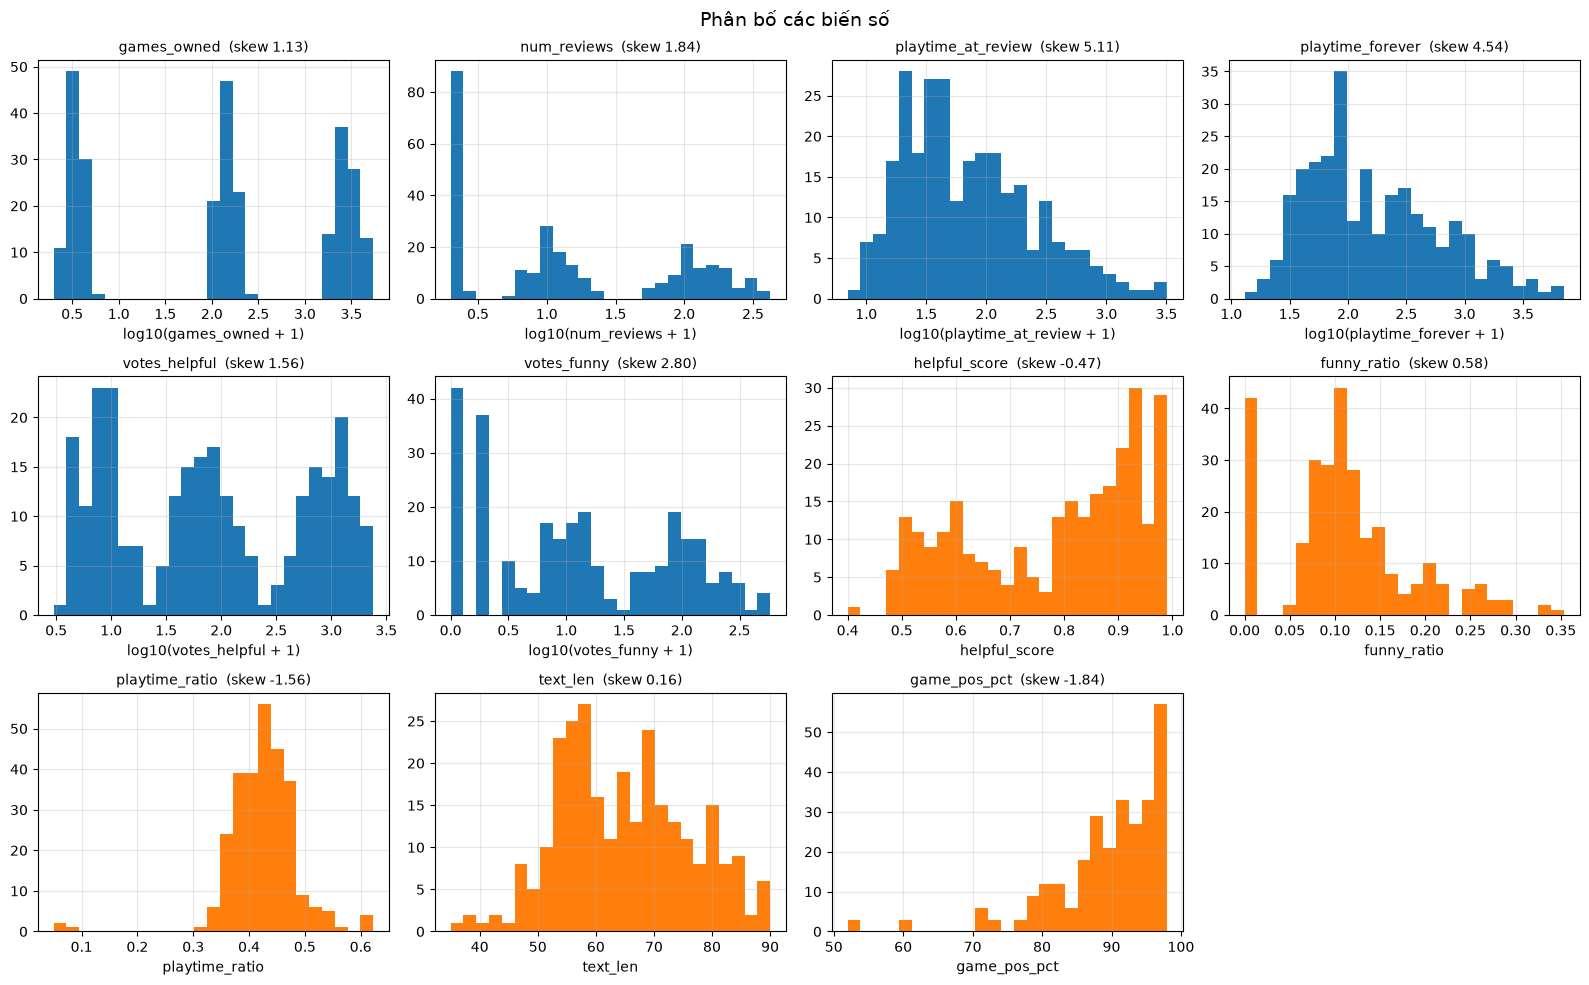

In [19]:
LOG_COLS = ["games_owned", "num_reviews", "playtime_at_review", "playtime_forever", "votes_helpful", "votes_funny"]
LIN_COLS = ["helpful_score", "funny_ratio", "playtime_ratio", "text_len", "game_pos_pct"]
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, c in zip(axes.flat, LOG_COLS + LIN_COLS):
    x = df[c].dropna()
    if c in LOG_COLS:
        ax.hist(np.log10(x + 1), bins=25, color="C0")
        ax.set_xlabel(f"log10({c} + 1)")
    else:
        ax.hist(x, bins=25, color="C1")
        ax.set_xlabel(c)
    ax.set_title(f"{c}  (skew {stats.skew(x):.2f})", fontsize=10)
axes.flat[-1].axis("off")
fig.suptitle("Phân bố các biến số", fontsize=14)
fig.tight_layout()
plt.show()

**Nhận xét (phân bố)**
- Các biến đếm (số game, số review, giờ chơi, vote) lệch phải mạnh, trải từ vài đơn vị đến hàng nghìn → dùng thang log.
- `games_owned` có 3 cụm tách rời (≈ 2 / ≈ 140 / ≈ 2.700) đúng theo 3 bậc reviewer, không có giá trị trung gian.
- `playtime_ratio` gần như hằng số (median 0,43, IQR 0,39–0,46): giờ chơi lúc viết luôn ≈ 40% tổng giờ chơi hiện tại.
- Review rất ngắn và đều (35–90 ký tự, 8–20 từ) vì là **trích đoạn**, không phải review đầy đủ.
- `game_pos_pct` lệch trái: phần lớn game 86–98% tích cực, chỉ vài game dưới 75%.

### 3.2 So sánh theo bậc reviewer (oldbie vs newbie)

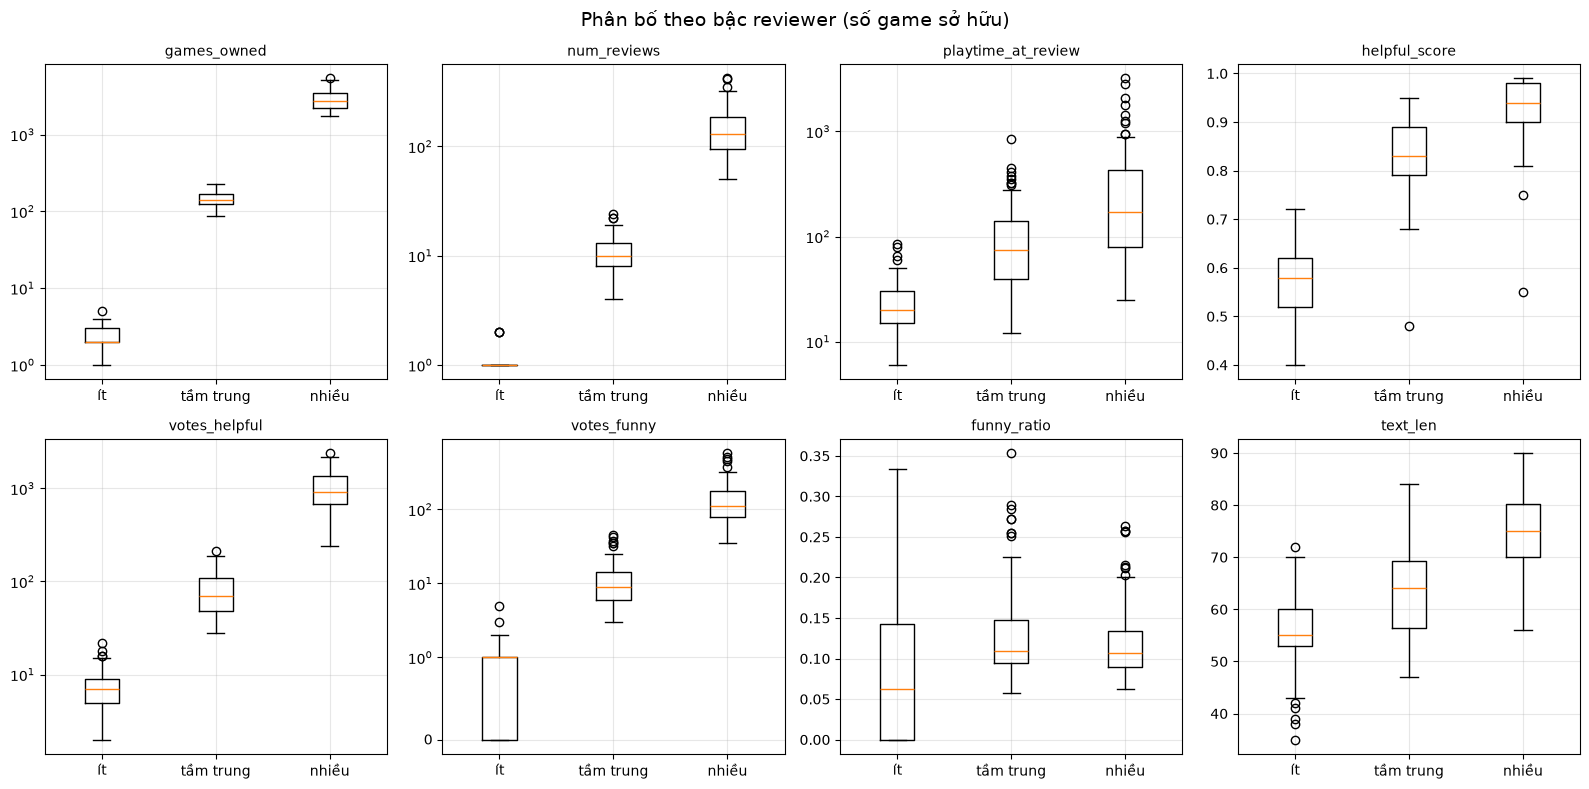

,n,pos_rate,games_owned_med,helpful_med,votes_helpful_med,funny_ratio_med,playtime_review_med,text_len_med
reviewer_tier,,,,,,,,
Ít game nhất,91,0.670,2.0,0.58,7.0,0.062,20.0,55.0
Tầm trung,92,0.935,142.5,0.83,70.0,0.109,75.0,64.0
Nhiều game nhất,92,1.000,2750.0,0.94,920.0,0.107,170.0,75.0


In [20]:
BOX_COLS = ["games_owned", "num_reviews", "playtime_at_review", "helpful_score",
            "votes_helpful", "votes_funny", "funny_ratio", "text_len"]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, c in zip(axes.flat, BOX_COLS):
    data = [df.loc[df.reviewer_tier == t, c].dropna() for t in TIER_ORDER]
    ax.boxplot(data, tick_labels=["ít", "tầm trung", "nhiều"], showfliers=True)
    if c in LOG_COLS:
        ax.set_yscale("symlog", linthresh=1)
    ax.set_title(c, fontsize=10)
fig.suptitle("Phân bố theo bậc reviewer (số game sở hữu)", fontsize=14)
fig.tight_layout()
plt.show()

summary = df.groupby("reviewer_tier", observed=True).agg(
    n=("steamid", "size"), pos_rate=("voted_up", "mean"), games_owned_med=("games_owned", "median"),
    helpful_med=("helpful_score", "median"), votes_helpful_med=("votes_helpful", "median"),
    funny_ratio_med=("funny_ratio", "median"), playtime_review_med=("playtime_at_review", "median"),
    text_len_med=("text_len", "median"))
display(summary.round(3))

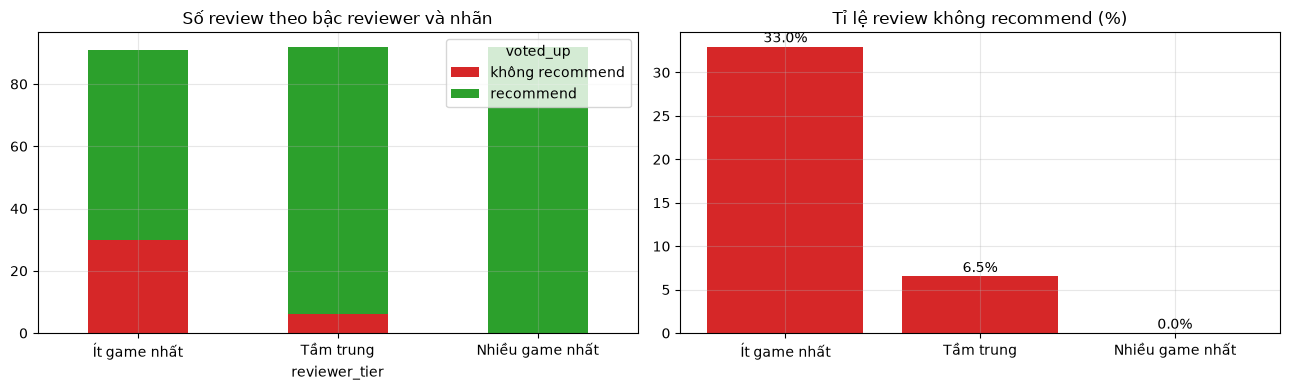

Chi-square bậc reviewer × voted_up: chi2 = 48.9, p = 2.4e-11


In [21]:
ct = pd.crosstab(df.reviewer_tier, df.voted_up)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ct.rename(columns={False: "không recommend", True: "recommend"}).plot.bar(stacked=True, ax=ax1, color=["C3", "C2"], rot=0)
ax1.set_title("Số review theo bậc reviewer và nhãn")
rate = 1 - df.groupby("reviewer_tier", observed=True).voted_up.mean()
ax2.bar(range(3), rate.values * 100, color="C3")
ax2.set_xticks(range(3), rate.index)
for i, v in enumerate(rate.values * 100):
    ax2.text(i, v + .5, f"{v:.1f}%", ha="center")
ax2.set_title("Tỉ lệ review không recommend (%)")
fig.tight_layout()
plt.show()

chi2, p, *_ = stats.chi2_contingency(ct)
print(f"Chi-square bậc reviewer × voted_up: chi2 = {chi2:.1f}, p = {p:.2g}")

**Nhận xét (theo bậc reviewer)**
- Bậc càng cao (càng nhiều game) thì giờ chơi lúc viết, điểm hữu ích, số vote hữu ích/hài hước và độ dài review càng cao;
  gần như không chồng lấn ở `games_owned`, `num_reviews`, `votes_helpful`, `helpful_score`.
- **Review không recommend tập trung ở newbie**: 33% ở bậc "Ít game", 6,5% ở "Tầm trung", **0%** ở "Nhiều game"
  (chi-square p ≈ 2e-11). Toàn bộ 92 review của bậc "Nhiều game" đều recommend.
- `funny_ratio` của bậc "Ít game" dao động mạnh vì số vote rất nhỏ (vd 1 funny / 3 helpful = 0,25) → tỉ lệ này
  chỉ đáng tin khi tổng vote đủ lớn.

### 3.3 Tương quan giữa các biến số

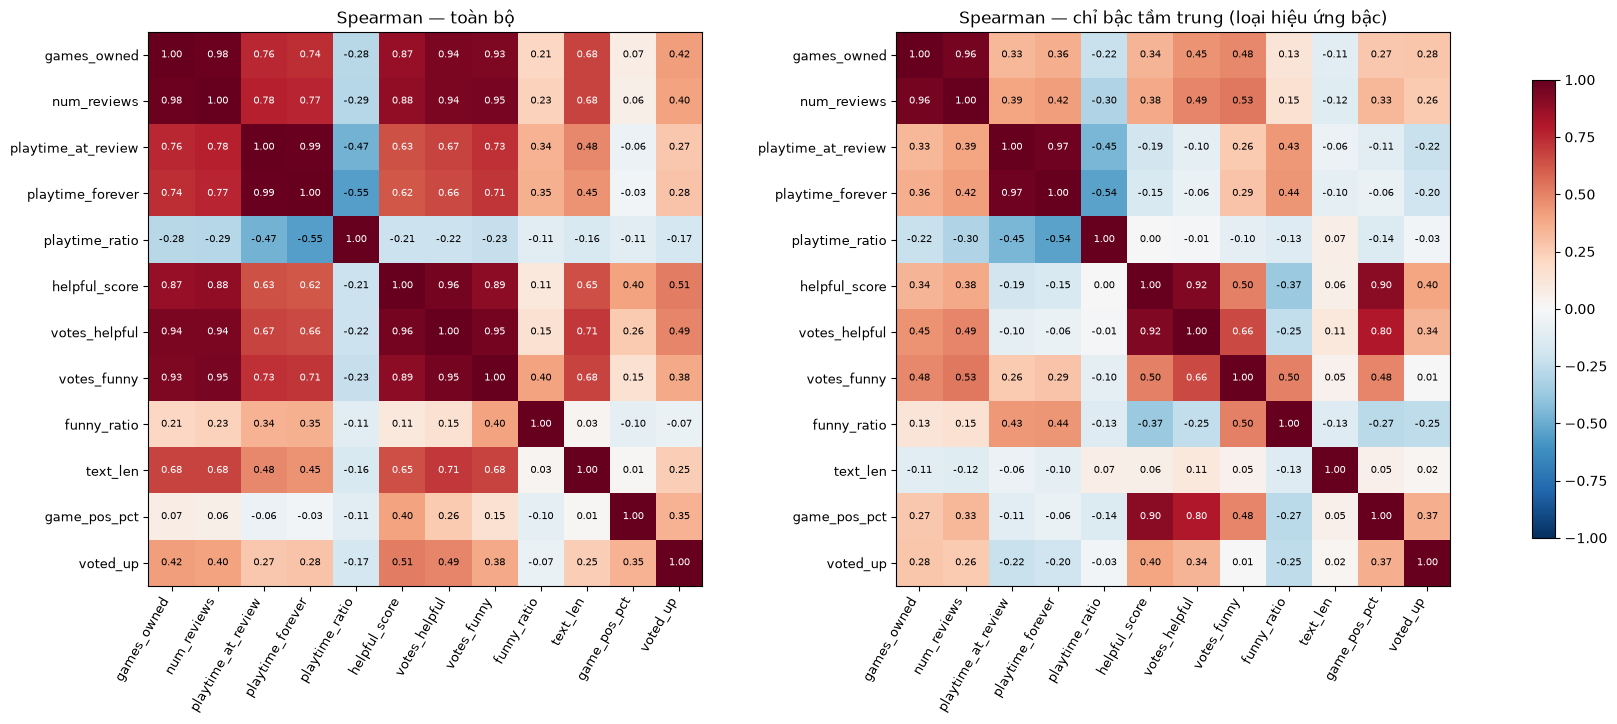

In [22]:
CORR_COLS = ["games_owned", "num_reviews", "playtime_at_review", "playtime_forever", "playtime_ratio",
             "helpful_score", "votes_helpful", "votes_funny", "funny_ratio", "text_len", "game_pos_pct", "voted_up"]

def corr_heatmap(data, title, ax):
    c = data[CORR_COLS].astype(float).corr(method="spearman")
    im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(c)), c.columns, rotation=60, ha="right", fontsize=9)
    ax.set_yticks(range(len(c)), c.columns, fontsize=9)
    ax.grid(False)
    for i in range(len(c)):
        for j in range(len(c)):
            ax.text(j, i, f"{c.iat[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(c.iat[i, j]) > .6 else "black")
    ax.set_title(title)
    return im

fig, axes = plt.subplots(1, 2, figsize=(21, 8.5), gridspec_kw={"wspace": .35})
corr_heatmap(df, "Spearman — toàn bộ", axes[0])
im = corr_heatmap(df[df.tier == "mid"], "Spearman — chỉ bậc tầm trung (loại hiệu ứng bậc)", axes[1])
fig.colorbar(im, ax=axes, shrink=.7)
plt.show()

Bậc reviewer được chọn theo số game sở hữu, nên các biến games_owned, num_reviews, votes… tương quan cao ở toàn bộ
dữ liệu có thể chỉ do **cách chọn mẫu theo bậc**. Heatmap bên phải chỉ lấy 1 bậc để xem quan hệ còn lại hay không.

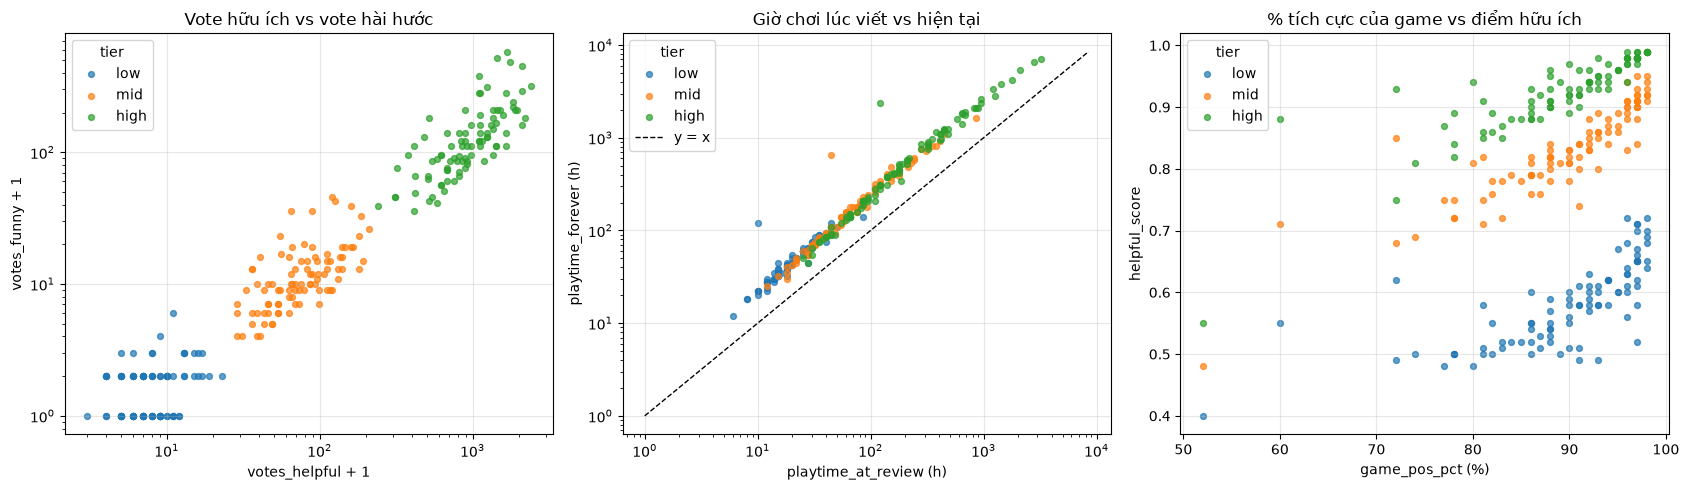

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
colors = {"low": "C0", "mid": "C1", "high": "C2"}
for t in ["low", "mid", "high"]:
    g = df[df.tier == t]
    axes[0].scatter(g.votes_helpful + 1, g.votes_funny + 1, s=18, alpha=.7, c=colors[t], label=t)
    axes[1].scatter(g.playtime_at_review, g.playtime_forever, s=18, alpha=.7, c=colors[t], label=t)
    axes[2].scatter(g.game_pos_pct, g.helpful_score, s=18, alpha=.7, c=colors[t], label=t)
axes[0].set(xscale="log", yscale="log", xlabel="votes_helpful + 1", ylabel="votes_funny + 1",
            title="Vote hữu ích vs vote hài hước")
lim = [1, df.playtime_forever.max() * 1.2]
axes[1].plot(lim, lim, "k--", lw=1, label="y = x")
axes[1].set(xscale="log", yscale="log", xlabel="playtime_at_review (h)", ylabel="playtime_forever (h)",
            title="Giờ chơi lúc viết vs hiện tại")
axes[2].set(xlabel="game_pos_pct (%)", ylabel="helpful_score", title="% tích cực của game vs điểm hữu ích")
for ax in axes:
    ax.legend(title="tier")
fig.tight_layout()
plt.show()

**Nhận xét (tương quan)**
- Trên toàn bộ dữ liệu, `games_owned`, `num_reviews`, `votes_helpful`, `votes_funny`, `helpful_score` tương quan rất cao
  với nhau (ρ 0,87–0,98). Khi chỉ xét bậc tầm trung, phần lớn quan hệ này giảm mạnh (vd games_owned ↔ votes_helpful
  0,94 → 0,45) → chủ yếu là **hiệu ứng bậc reviewer**, không phải quan hệ bên trong từng nhóm.
- `num_reviews` ↔ `games_owned` vẫn rất cao trong cùng bậc (0,96); `playtime_at_review` ↔ `playtime_forever` ≈ 0,97–0,99
  → mỗi cặp chỉ nên dùng 1 biến làm feature.
- **`helpful_score` ↔ `game_pos_pct` = 0,90 trong cùng bậc**: điểm hữu ích của review gần như do % tích cực của game
  quyết định (biểu đồ phải: 3 dải song song theo bậc, cùng tăng theo % game). Ngoài đời điểm hữu ích phụ thuộc nội dung
  review hơn là game → dấu hiệu dữ liệu sinh theo công thức; thận trọng khi dùng `helpful_score` làm nhãn
  cho mô hình "chấm mức hữu ích".
- `voted_up` tương quan dương với `helpful_score` (0,51) và `game_pos_pct` (0,35).
- Vote hài hước tăng gần tuyến tính theo vote hữu ích (biểu đồ trái); không review nào có funny vượt hẳn helpful
  → **không thấy review troll/mỉa mai rõ ràng** trong mẫu này.

### 3.4 Nhãn `voted_up` theo các biến

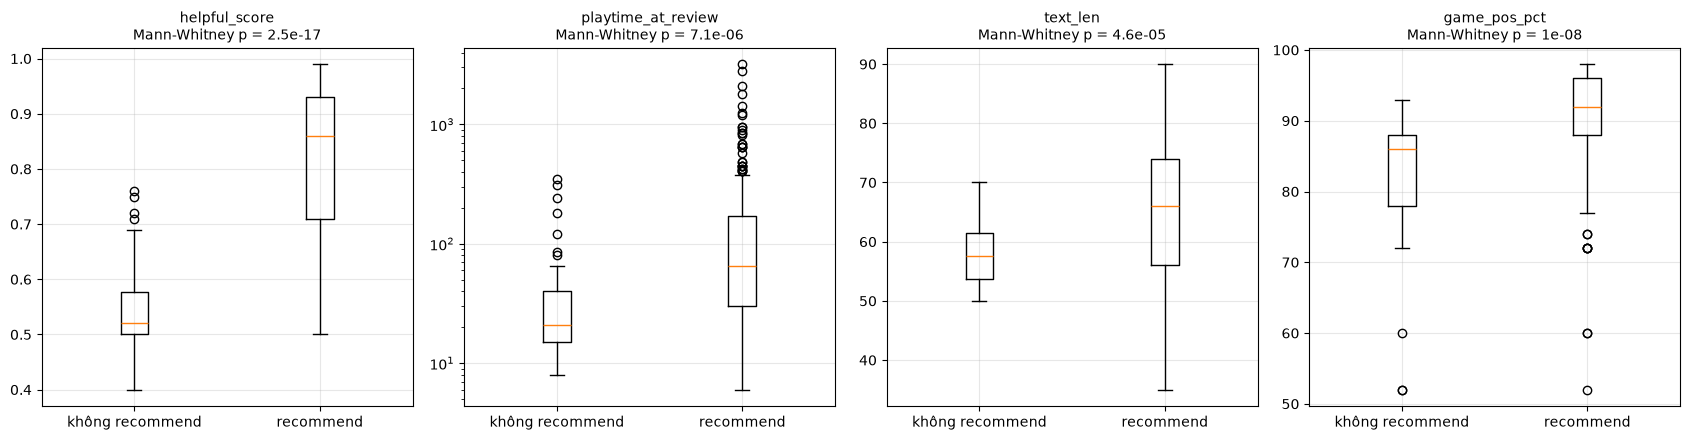

helpful_score       votes_helpful        game_pos_pct      
voted_up                False True          False  True         False True 
reviewer_tier                                                              
Ít game nhất             0.51  0.60           4.5    8.0         86.5  94.0
Tầm trung                0.72  0.84          36.5   75.0         76.0  92.0
Nhiều game nhất           NaN  0.94           NaN  920.0          NaN  91.0

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
for ax, c in zip(axes, ["helpful_score", "playtime_at_review", "text_len", "game_pos_pct"]):
    data = [df.loc[df.voted_up == v, c] for v in (False, True)]
    ax.boxplot(data, tick_labels=["không recommend", "recommend"])
    if c == "playtime_at_review":
        ax.set_yscale("log")
    u = stats.mannwhitneyu(*data)
    ax.set_title(f"{c}\nMann-Whitney p = {u.pvalue:.2g}", fontsize=10)
fig.tight_layout()
plt.show()

# trong cùng bậc (loại hiệu ứng bậc)
display(df.groupby(["reviewer_tier", "voted_up"], observed=True)[["helpful_score", "votes_helpful", "game_pos_pct"]]
          .median().unstack().round(2))

**Nhận xét (theo nhãn)**
- Review không recommend có điểm hữu ích thấp hơn, giờ chơi lúc viết ít hơn và thuộc game có % tích cực thấp hơn.
  Độ dài review gần như không khác.
- Một phần khác biệt đến từ việc review negative chủ yếu là của newbie. Tuy nhiên **ngay trong cùng bậc**, review
  negative vẫn có `helpful_score` thấp hơn (0,51 vs 0,60 ở bậc ít; 0,72 vs 0,84 ở bậc tầm trung) và thuộc game có % thấp hơn.

### 3.5 Theo game, thể loại và nhà phát hành

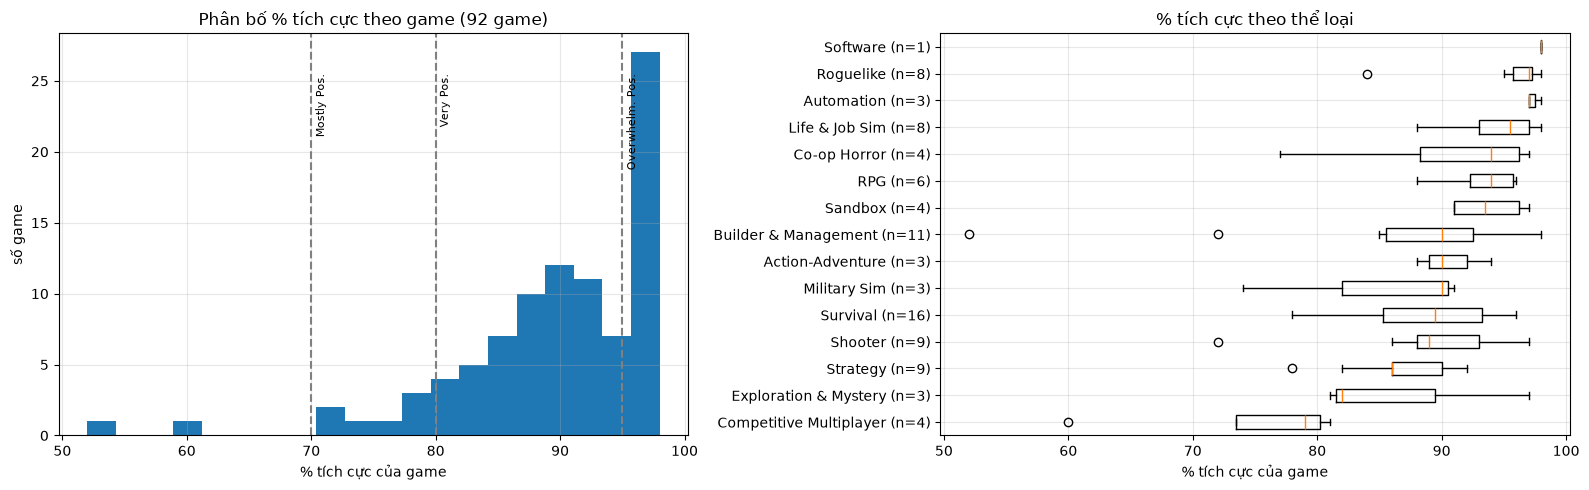

Game % tích cực thấp nhất / cao nhất:


,game_name,publisher,genre,game_pos_pct
58,Cities: Skylines II,Paradox Interactive,Builder & Management,52.0
45,PUBG: BATTLEGROUNDS,"KRAFTON, Inc.",Competitive Multiplayer,60.0
44,Helldivers 2,PlayStation Publishing,Shooter,72.0
81,Frostpunk 2,11 bit studios,Builder & Management,72.0
14,War Thunder,Gaijin Entertainment,Military Sim,74.0
26,RimWorld,Ludeon Studios,Builder & Management,98.0
36,Stardew Valley,ConcernedApe,Life & Job Sim,98.0
37,Factorio,Wube Software,Automation,98.0
38,Wallpaper Engine,Wallpaper Engine Team,Software,98.0
68,Hades,Supergiant Games,Roguelike,98.0


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].hist(games.game_pos_pct, bins=20, color="C0")
for thr, lab in [(70, "Mostly Pos."), (80, "Very Pos."), (95, "Overwhelm. Pos.")]:
    axes[0].axvline(thr, ls="--", c="gray")
    axes[0].text(thr + .3, axes[0].get_ylim()[1] * .9, lab, fontsize=8, rotation=90, va="top")
axes[0].set(xlabel="% tích cực của game", ylabel="số game", title="Phân bố % tích cực theo game (92 game)")

order = games.groupby("genre").game_pos_pct.median().sort_values().index
axes[1].boxplot([games.loc[games.genre == g, "game_pos_pct"] for g in order], orientation="horizontal",
                tick_labels=[f"{g} (n={(games.genre == g).sum()})" for g in order])
axes[1].set(xlabel="% tích cực của game", title="% tích cực theo thể loại")
fig.tight_layout()
plt.show()

print("Game % tích cực thấp nhất / cao nhất:")
display(pd.concat([games.nsmallest(5, "game_pos_pct"), games.nlargest(5, "game_pos_pct")])
          [["game_name", "publisher", "genre", "game_pos_pct"]])

**Nhận xét (game, thể loại)**
- 92 game có % tích cực median 91%; thấp nhất là Cities: Skylines II (52%), PUBG (60%), Helldivers 2 và Frostpunk 2 (72%).
- Thể loại có % cao và đồng đều: Roguelike, Automation, Sandbox, Life & Job Sim.
  Thể loại có % thấp hơn và phân tán: Competitive Multiplayer, Military Sim, Builder & Management (do Cities: Skylines II).
- Nhiều thể loại chỉ có 3–4 game → so sánh giữa thể loại chỉ mang tính tham khảo.

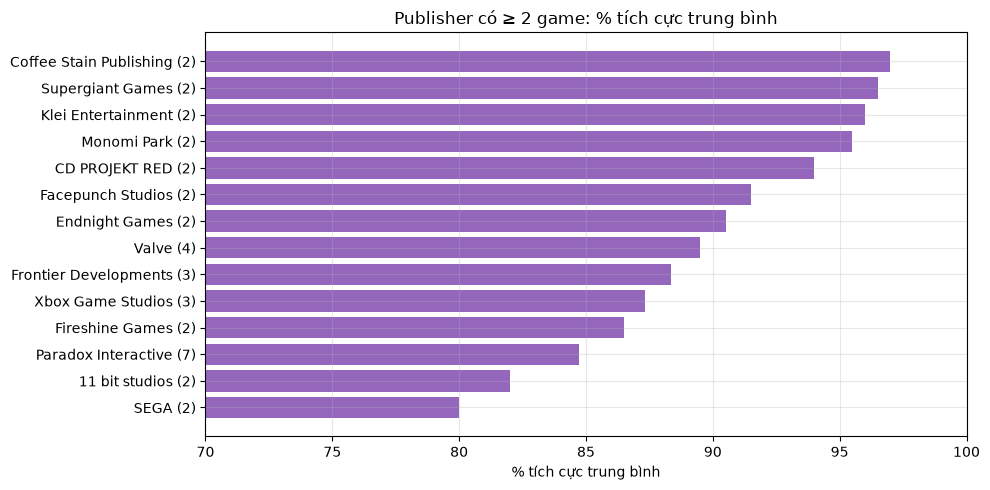

,n_games,mean_pos,games
publisher,,,
SEGA,2,80.0,"Total War: THREE KINGDOMS, Total War: WARHAMMER III"
11 bit studios,2,82.0,"Frostpunk, Frostpunk 2"
Paradox Interactive,7,84.7,"Crusader Kings II, Europa Universalis IV, Cities: Skylines, Stellaris, Heart..."
Fireshine Games,2,86.5,"Shadows of Doubt, Core Keeper"
Xbox Game Studios,3,87.3,"Sea of Thieves, Age of Empires IV: Anniversary Edition, Forza Horizon 5"
Frontier Developments,3,88.3,"Planet Coaster, Planet Zoo, Jurassic World Evolution 2"
Valve,4,89.5,"Team Fortress 2, Left 4 Dead 2, Dota 2, Counter-Strike 2"
Endnight Games,2,90.5,"The Forest, Sons Of The Forest"
Facepunch Studios,2,91.5,"Garry's Mod, Rust"


In [26]:
pub = (games.groupby("publisher")
            .agg(n_games=("app_id", "size"), mean_pos=("game_pos_pct", "mean"),
                 games=("game_name", lambda s: ", ".join(s)))
            .query("n_games >= 2").sort_values("mean_pos"))
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(pub.index + " (" + pub.n_games.astype(str) + ")", pub.mean_pos, color="C4")
ax.set_xlim(pub.mean_pos.min() - 10, 100)
ax.set(xlabel="% tích cực trung bình", title="Publisher có ≥ 2 game: % tích cực trung bình")
fig.tight_layout()
plt.show()
display(pub.round(1))

**Nhận xét (publisher)**
- 69 publisher nhưng chỉ 14 publisher có ≥ 2 game; Paradox (7 game) là nhóm lớn nhất. Phần lớn publisher chỉ có 1 game
  → gom theo publisher cho ít cặp "cùng nhóm"; gom theo **thể loại** cho nhóm lớn hơn (3–16 game).
- Publisher có bản kế nhiệm bị chê thì % trung bình thấp (Paradox với Cities: Skylines II, 11 bit với Frostpunk 2).

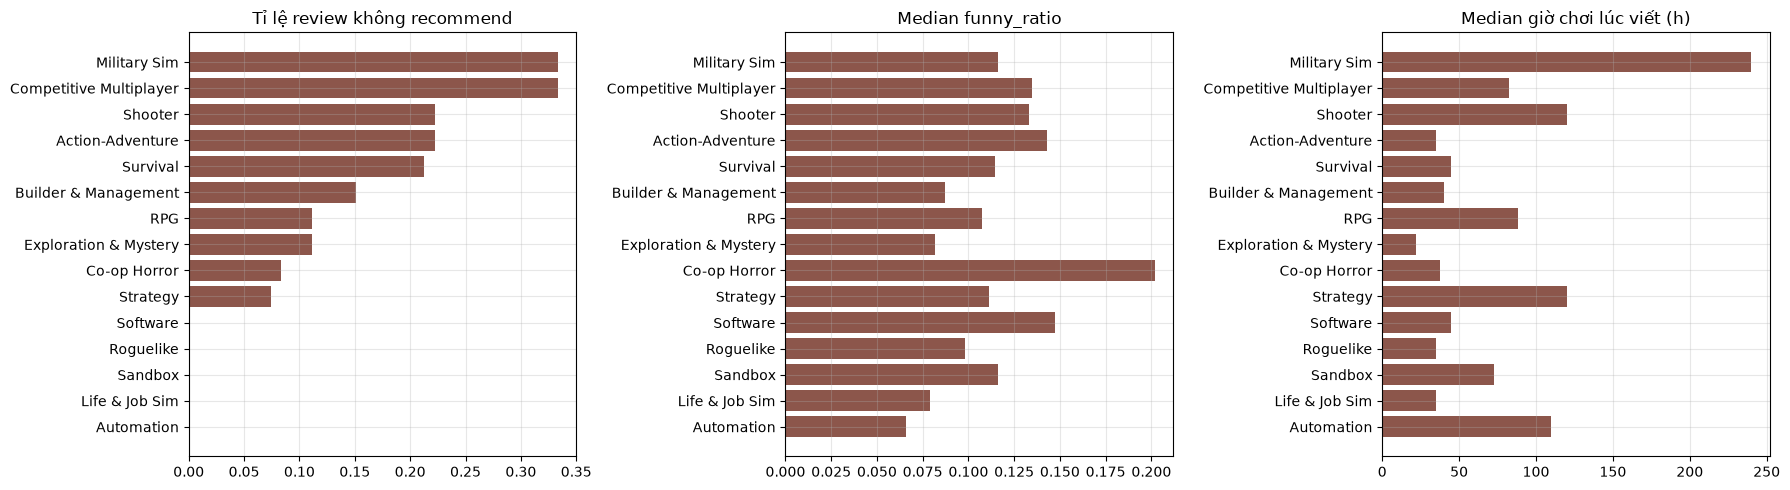

,n_reviews,neg_rate,funny_ratio,helpful,playtime_review
genre,,,,,
Automation,9,0.000,0.066,0.900,110.0
Life & Job Sim,24,0.000,0.079,0.880,35.0
Sandbox,12,0.000,0.116,0.860,72.5
Roguelike,24,0.000,0.098,0.900,35.0
Software,3,0.000,0.147,0.920,45.0
Strategy,27,0.074,0.111,0.800,120.0
Co-op Horror,12,0.083,0.202,0.840,37.5
Exploration & Mystery,9,0.111,0.081,0.820,22.0
RPG,18,0.111,0.107,0.885,88.5


In [27]:
gg = df.groupby("genre").agg(n_reviews=("steamid", "size"), neg_rate=("voted_up", lambda s: 1 - s.mean()),
                             funny_ratio=("funny_ratio", "median"), helpful=("helpful_score", "median"),
                             playtime_review=("playtime_at_review", "median")).sort_values("neg_rate")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, c, t in zip(axes, ["neg_rate", "funny_ratio", "playtime_review"],
                    ["Tỉ lệ review không recommend", "Median funny_ratio", "Median giờ chơi lúc viết (h)"]):
    ax.barh(gg.index, gg[c], color="C5")
    ax.set_title(t)
fig.tight_layout()
plt.show()
display(gg.round(3))

**Nhận xét (review theo thể loại)**
- Tỉ lệ review không recommend cao nhất ở Competitive Multiplayer và Military Sim (33%), rồi Shooter, Action-Adventure,
  Survival (21–22%) — các thể loại online, có PvP. 5 thể loại không có review negative nào.
- Co-op Horror có `funny_ratio` cao nhất (median 0,20), hợp với tính chất game hài khi chơi nhóm (Lethal Company, Content Warning).
- Military Sim và Shooter có giờ chơi lúc viết cao nhất (median 240h, 120h).

### 3.6 Khía cạnh được nhắc trong review
Đếm từ khoá tiếng Việt theo khía cạnh (đồ hoạ, âm thanh, cốt truyện, gameplay, kỹ thuật/lỗi, cộng đồng, độ khó, giá).
Danh sách từ khoá tự chọn, chỉ để có cái nhìn sơ bộ.

,n,% trong review recommend,% trong review không recommend
gameplay,37,14.2,8.3
cày/giá,32,11.7,11.1
đồ hoạ,31,13.0,0.0
co-op/bạn bè,27,10.5,5.6
âm thanh,20,8.4,0.0
cốt truyện,19,7.9,0.0
kỹ thuật/lỗi,17,3.3,25.0
độ khó/người mới,16,4.6,13.9
cộng đồng/hack,9,2.1,11.1


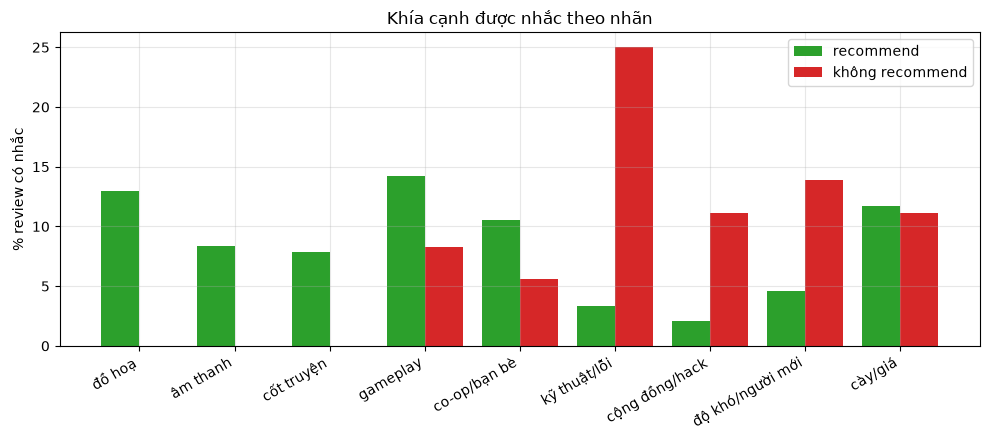

In [28]:
ASPECTS = {
    "đồ hoạ": r"đồ họa|đồ hoạ|hình ảnh|pixel|phong cách nghệ thuật|đẹp",
    "âm thanh": r"âm thanh|âm nhạc|nhạc|lồng tiếng",
    "cốt truyện": r"cốt truyện|nhân vật|nhiệm vụ|câu chuyện",
    "gameplay": r"lối chơi|gameplay|cơ chế|chiến đấu|vòng lặp",
    "co-op/bạn bè": r"co-op|bạn bè|nhóm|đồng đội",
    "kỹ thuật/lỗi": r"lỗi|lag|giật|văng|tối ưu|hiệu năng|cấu hình|dung lượng|tải game",
    "cộng đồng/hack": r"cộng đồng|toxic|hack|cheat|bot",
    "độ khó/người mới": r"khó|người mới|ngợp|rắc rối",
    "cày/giá": r"cày|giá|dlc|miễn phí|vip|đáng tiền",
}
low = df.review_text.str.lower()
asp = pd.DataFrame({a: low.str.contains(p, regex=True) for a, p in ASPECTS.items()})
asp_tbl = pd.DataFrame({"n": asp.sum(), "% trong review recommend": asp[df.voted_up].mean() * 100,
                        "% trong review không recommend": asp[~df.voted_up].mean() * 100}).round(1)
display(asp_tbl.sort_values("n", ascending=False))

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(asp_tbl))
ax.bar(x - .2, asp_tbl.iloc[:, 1], .4, label="recommend", color="C2")
ax.bar(x + .2, asp_tbl.iloc[:, 2], .4, label="không recommend", color="C3")
ax.set_xticks(x, asp_tbl.index, rotation=30, ha="right")
ax.set(ylabel="% review có nhắc", title="Khía cạnh được nhắc theo nhãn")
ax.legend()
fig.tight_layout()
plt.show()

**Nhận xét (khía cạnh)**
- Review recommend nhắc nhiều tới gameplay, đồ hoạ, co-op/bạn bè, âm thanh, cốt truyện. Không review negative nào
  nhắc đồ hoạ, âm thanh hay cốt truyện.
- Review không recommend tập trung vào **kỹ thuật/lỗi** (25%, so với 3% ở review recommend), **độ khó/người mới** (14%)
  và **cộng đồng/hack** (11%) → khớp với việc negative chủ yếu đến từ newbie.

## 4. Lưu dữ liệu sạch

In [29]:
df.to_csv("data/v2_reviews_clean.csv", index=False, encoding="utf-8-sig")
games[["app_id", "rank", "game_name", "publisher", "genre", "is_game", "game_pos_pct"]].to_csv(
    "data/v2_games.csv", index=False, encoding="utf-8-sig")
print("Đã ghi data/v2_reviews_clean.csv", df.shape, "và data/v2_games.csv", games.shape)

Đã ghi data/v2_reviews_clean.csv (275, 23) và data/v2_games.csv (92, 7)


## 5. Tổng kết

**Làm sạch**: 299 → **275 review / 92 game** (bỏ 8 game lặp). Thêm `user_id`, `voted_up` (suy từ thứ tự chữ ở cột đánh giá),
`game_pos_pct`, `funny_ratio`, `playtime_ratio`, độ dài text. Publisher: 79 game lấy từ v1 + 13 game điền tay.
Thể loại: gán tay 15 nhóm. Wallpaper Engine đánh dấu `is_game = False`.

**Insight chính**
1. Newbie (ít game) là nguồn chính của review không recommend (33%); oldbie (nhiều game) 100% recommend.
2. Newbie phàn nàn về lỗi kỹ thuật, độ khó, hack/cộng đồng; review recommend khen gameplay, đồ hoạ, âm thanh, cốt truyện.
3. Thể loại online/PvP (Competitive, Military Sim, Shooter, Survival) có tỉ lệ review negative cao hơn hẳn;
   Roguelike, Automation, Sandbox, Life Sim gần như toàn khen.
4. Không thấy review troll rõ ràng: vote hài hước tỉ lệ thuận với vote hữu ích.

**Hạn chế của dữ liệu** (cần nói rõ khi báo cáo)
- Steam ID mất chính xác (lưu dạng float), có 1 va chạm ID → không tra ngược được tài khoản thật.
- Mỗi user chỉ có 1 review → không làm collaborative filtering; gợi ý phải dựa trên **nhóm game** (content-based).
- Không có cột recommend gốc; `voted_up` là suy luận (đã đọc kiểm tra, khớp nội dung).
- Nhiều dấu hiệu dữ liệu được sinh theo mẫu: đúng 3 reviewer/game, `playtime_ratio` ≈ 0,43 cho mọi dòng,
  `helpful_score` gần như do % của game quyết định, review là trích đoạn tiếng Việt ngắn và đều
  → phù hợp làm **dữ liệu minh hoạ** cho demo gom nhóm và gợi ý; không nên diễn giải các con số như thống kê Steam thật.
- Text tiếng Việt → model sentiment train trên `steam_reviews.csv` (tiếng Anh) không áp trực tiếp được.

**Bước tiếp theo**: dùng `data/v2_games.csv` + `data/v2_reviews_clean.csv` để vẽ đồ thị nhóm game theo
publisher/thể loại và làm hàm gợi ý: user recommend game X → các game cùng nhóm, xếp theo `game_pos_pct`.